In [1]:
from __future__ import annotations

from typing import List, Tuple
import numpy as np
import qutip as qt


# ============================================================
# Local operators
# ============================================================

def op_on_site(op: qt.Qobj, N: int, site: int) -> qt.Qobj:
    if not (0 <= site < N):
        raise ValueError("site out of range")
    ops = [qt.qeye(2)] * N
    ops[site] = op
    return qt.tensor(ops)


def two_site_op(opA: qt.Qobj, opB: qt.Qobj, N: int, i: int, j: int) -> qt.Qobj:
    if i == j:
        raise ValueError("i and j must differ")
    ops = [qt.qeye(2)] * N
    ops[i] = opA
    ops[j] = opB
    return qt.tensor(ops)


# ============================================================
# Hamiltonian
# ============================================================

def kac_factor(N: int, alpha: float) -> float:
    r = np.arange(1, N, dtype=float)
    return np.sum((N - r) / (r ** alpha)) / (N - 1)


def build_H_B_Jz_Jlong(
    N: int,
    Bz: float,
    Jz: float,
    Jx: float,
    alpha: float,
    kac: bool = True,
) -> qt.Qobj:

    if N < 2:
        raise ValueError("N must be >= 2")

    sx, sz = qt.sigmax(), qt.sigmaz()
    H = 0

    # Kac normalization
    if kac:
        Jx = Jx / kac_factor(N, alpha)

    # field
    for j in range(N):
        H += Bz * op_on_site(sz, N, j)

    # zz nearest neighbor
    for j in range(N - 1):
        H += Jz * two_site_op(sz, sz, N, j, j + 1)

    # xx long-range
    if alpha >= 100:
        for j in range(N - 1):
            H += Jx * two_site_op(sx, sx, N, j, j + 1)
    else:
        for i in range(N):
            for j in range(i + 1, N):
                r = j - i
                H += (Jx / (r ** alpha)) * two_site_op(sx, sx, N, i, j)

    return H


# ============================================================
# Diagonalization
# ============================================================

def diagonalize(H: qt.Qobj):
    evals, evecs = H.eigenstates()
    return np.array(evals), evecs


# ============================================================
# Product states
# ============================================================

def product_state_angles(thetas: np.ndarray, phis: np.ndarray) -> qt.Qobj:
    thetas = np.asarray(thetas)
    phis = np.asarray(phis)

    if thetas.shape != phis.shape:
        raise ValueError("shape mismatch")

    kets = [
        np.cos(t / 2) * qt.basis(2, 0)
        + np.exp(1j * p) * np.sin(t / 2) * qt.basis(2, 1)
        for t, p in zip(thetas, phis)
    ]

    return qt.tensor(kets).unit()


def product_state_x_pm(pm: str) -> qt.Qobj:
    pm = pm.strip()

    N = len(pm)
    thetas = np.full(N, np.pi / 2)
    phis = np.array([0 if c == "+" else np.pi for c in pm])

    return product_state_angles(thetas, phis)


def product_state_from_bitstring(bits: str) -> qt.Qobj:
    bits = bits.strip()

    kets = [qt.basis(2, int(b)) for b in bits]
    return qt.tensor(kets).unit()


# ============================================================
# Fidelity from spectrum
# ============================================================

def fidelity_from_spectrum(
    evals: np.ndarray,
    coeffs: np.ndarray,
    times: np.ndarray
) -> np.ndarray:

    weights = np.abs(coeffs) ** 2

    F = np.zeros(len(times))

    for k, t in enumerate(times):
        amp = np.sum(weights * np.exp(-1j * evals * t))
        F[k] = np.abs(amp) ** 2

    return F

In [4]:
np.linspace(0, 10, 11)

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

In [2]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt

N = 5
Jx = 100
Jz = 1.0
Bz = 1.0
gamma = 0.1

alphas = [0.1, 4, 1000]

tmax = 1000
times = np.linspace(0, tmax, 5000)

psi0 = product_state_x_pm("+-" + "+"*(N-2))
rho0 = psi0 * psi0.dag()

F_dict = {}

for alpha in alphas:

    H = build_H_B_Jz_Jlong(N, Bz, Jz, Jx, alpha, kac=False)

    # collective DFS-compatible noise
    c_ops = [
        np.sqrt(gamma) * sum(op_on_site(qt.sigmax(), N, i) for i in range(N))
    ]

    result = qt.mesolve(H, rho0, times, c_ops, [])
    rhos = result.states

    F_t = np.array([qt.expect(rho0, rho) for rho in rhos])

    F_dict[alpha] = F_t

C:\Users\shrey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\qutip\solver\solver_base.py:598: FutureWarning: e_ops will be keyword only from qutip 5.3 for all solver
  warnings.warn(


C:\Users\shrey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\shrey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


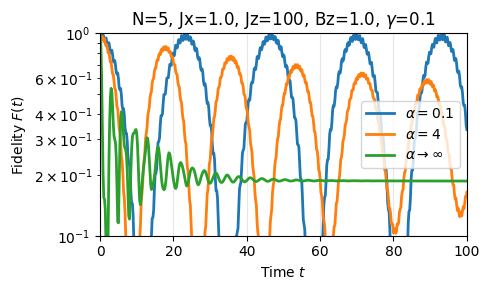

In [6]:
plt.figure(figsize=(5,3))

for alpha, F_t in F_dict.items():
    if alpha<100:
        label = fr"$\alpha={alpha}$"
    else:
        label = fr"$\alpha\to\infty$"
    plt.semilogy(times, F_t, lw=2, label=label)

plt.xlabel("Time $t$")
plt.xlim(0,100)
plt.ylim(1e-1,1)
plt.ylabel("Fidelity $F(t)$")
N = 5
Jx = 100
Jz = 1.0
Bz = 1.0
gamma = 0.1
plt.title(fr"N={N}, Jx={Jz}, Jz={Jx}, Bz={Bz}, $\gamma$={gamma}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plt/dfs_fidelity_strong_diss.pdf")
plt.show()

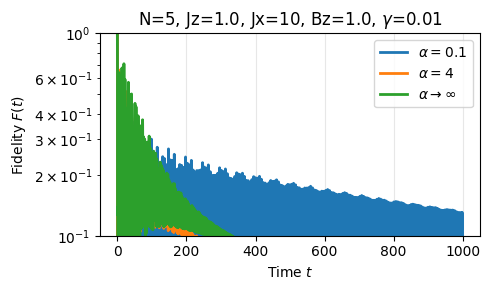

In [ ]:
plt.figure(figsize=(5,3))

for alpha, F_t in F_dict.items():
    if alpha<100:
        label = fr"$\alpha={alpha}$"
    else:
        label = fr"$\alpha\to\infty$"
    plt.semilogy(times, F_t, lw=2, label=label)

plt.xlabel("Time $t$")
plt.ylim(1e-1,1)
plt.ylabel("Fidelity $F(t)$")
N = 5
Jx = 100
Jz = 1.0
Bz = 1.0
gamma = 0.01
plt.title(fr"N={N}, Jz={Jz}, Jx={Jx}, Bz={Bz}, $\gamma$={gamma}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plt/dfs_fidelity.pdf")
plt.show()

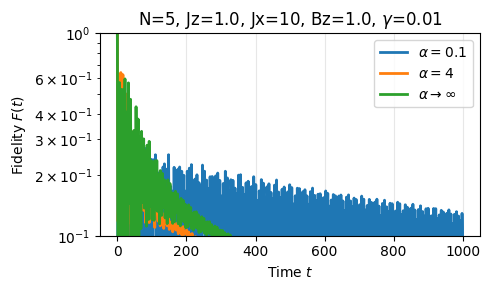

In [21]:
plt.figure(figsize=(5,3))

for alpha, F_t in F_dict.items():
    if alpha<100:
        label = fr"$\alpha={alpha}$"
    else:
        label = fr"$\alpha\to\infty$"
    plt.semilogy(times, F_t, lw=2, label=label)

plt.xlabel("Time $t$")
plt.ylim(1e-1,1)
plt.ylabel("Fidelity $F(t)$")
N = 5
Jx = 10
Jz = 1.0
Bz = 1.0
gamma = 0.01
plt.title(fr"N={N}, Jz={Jz}, Jx={Jx}, Bz={Bz}, $\gamma$={gamma}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plt/dfs_fidelity_weak.pdf")
plt.show()